In [20]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, precision_recall_curve, roc_auc_score, average_precision_score
import matplotlib.pyplot as plt

In [21]:
#GPU 사용 가능 여부 확인
USE_CUDA = torch.cuda.is_available()
print('GPU 사용 가능 여부:', USE_CUDA)

GPU 사용 가능 여부: True


In [22]:
#사용할 디바이스 설정 (GPU 또는 CPU)
device = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda:1


In [23]:
# ===== 전체 데이터 로드 — nested 5-fold CV =====
# 기존에는 train_452 / test_158 을 따로 로드했지만,
# 이제 전체 610개 데이터를 한 번에 로드하고 5-fold로 나눠서
# 각 fold가 정확히 한 번씩 최종 test가 되도록 한다.
all_data = pd.read_csv('dataset.csv')

# 'Class' 열 숫자 인코딩
label_encoder = LabelEncoder()
all_data['Class'] = label_encoder.fit_transform(all_data['Class'])
class_mapping = {index: label for index, label in enumerate(label_encoder.classes_)}
print('label mapping:', class_mapping)
print('전체 샘플 수:', len(all_data))
print(all_data['Class'].value_counts().sort_index())

label mapping: {0: 'de', 1: 'f', 2: 'nor'}
전체 샘플 수: 622
0    250
1    195
2    177
Name: Class, dtype: int64


In [24]:
#onehot 파일 폴더 경로
onehot_folder = 'onehot_7'
onehot_files = os.listdir(onehot_folder)

# 원핫인코딩 매트릭스를 저장할 딕셔너리
onehot_matrices = {}

# 최대 행 수 찾기
max_rows = 0

# 원핫인코딩 매트릭스 파일들을 로드 (헤더 없음)
for file in onehot_files:
    variant_name = file.split('.csv')[0].replace('_', '.')  # CYP2D6_1.001.csv -> CYP2D6.1.001
    file_path = os.path.join(onehot_folder, file)
    try:
        matrix = pd.read_csv(file_path, header=None).values
        onehot_matrices[variant_name] = matrix
        max_rows = max(max_rows, matrix.shape[0])
        print(f"Loaded {variant_name}: shape {matrix.shape}")
    except Exception as e:
        print(f"Error loading {file}: {str(e)}")

print(f"최대 행 수: {max_rows}")
print(f"로드된 매트릭스 개수: {len(onehot_matrices)}")

Loaded CYP2D6.106.002: shape (4312, 7)
Loaded CYP2D6.35.004: shape (4312, 7)
Loaded CYP2D6.2.004: shape (4312, 7)
Loaded CYP2D6.4.012: shape (4312, 7)
Loaded CYP2D6.36.002: shape (4312, 7)
Loaded CYP2D6.10.003: shape (4312, 7)
Loaded CYP2D6.1.050: shape (4312, 7)
Loaded CYP2D6.105.001: shape (4312, 7)
Loaded CYP2D6.159.001: shape (4312, 7)
Loaded CYP2D6.134.001: shape (4312, 7)
Loaded CYP2D6.155.001: shape (4312, 7)
Loaded CYP2D6.4.015: shape (4312, 7)
Loaded CYP2D6.11.001: shape (4312, 7)
Loaded CYP2D6.71.001: shape (4312, 7)
Loaded CYP2D6.4.003: shape (4312, 7)
Loaded CYP2D6.47.001: shape (4312, 7)
Loaded CYP2D6.4.010: shape (4312, 7)
Loaded CYP2D6.4.024: shape (4312, 7)
Loaded CYP2D6.2.015: shape (4312, 7)
Loaded CYP2D6.164.001: shape (4312, 7)
Loaded CYP2D6.85.001: shape (4312, 7)
Loaded CYP2D6.3.002: shape (4312, 7)
Loaded CYP2D6.1.035: shape (4312, 7)
Loaded CYP2D6.3.003: shape (4312, 7)
Loaded CYP2D6.97.001: shape (4312, 7)
Loaded CYP2D6.1.013: shape (4312, 7)
Loaded CYP2D6.4.00

In [25]:
# 매트릭스 패딩 함수_원래 input으로 들어갈 X가 numpy 배열이었는데 이를 pytorch 텐서로 전환
def pad_matrix(matrix, target_rows=4330, target_cols=7):
    current_rows, current_cols = matrix.shape
    padded = torch.zeros((target_rows, target_cols))
    padded[:current_rows, :current_cols] = torch.tensor(matrix)
    return padded

# 패딩된 매트릭스로 업데이트
for key in onehot_matrices:
    onehot_matrices[key] = pad_matrix(onehot_matrices[key])


# 'Variant' 컬럼의 값을 기반으로 원핫인코딩 매트릭스 매핑
def map_variant_to_onehot(variant):
    variants = [v.strip() for v in str(variant).split(';') if v.strip()]  # '; ' / ';' 모두 처리
    matrices = []
    for v in variants:
        if v in onehot_matrices:
            matrices.append(onehot_matrices[v])
        else:
            print(f"Warning: Matrix not found for variant {v}")
            matrices.append(torch.zeros((4330, 7)))

    # 변이가 2개 미만인 경우 0으로 채우기
    while len(matrices) < 2:
        matrices.append(torch.zeros((4330, 7)))

    # 첫 두 개의 매트릭스를 행 방향으로 이어붙임
    combined_matrix = torch.vstack(matrices[:2])
    return combined_matrix

# 데이터셋마다 매핑된 매트릭스를 생성하는 함수
def map_variants_to_tensor(data):
    mapped_matrices = []
    for variant in data['Variant']:
        mapped_matrices.append(map_variant_to_onehot(variant))
    X = torch.stack(mapped_matrices)
    y = torch.tensor(data['Class'].values)
    return X, y

# 전체 610개 데이터를 텐서로 변환 (fold 분할은 아래에서 인덱스로 수행)
full_X, full_y = map_variants_to_tensor(all_data)
print("Full X shape:", full_X.shape)
print("Full y shape:", full_y.shape)

Full X shape: torch.Size([622, 8660, 7])
Full y shape: torch.Size([622])


In [26]:
# 데이터셋 정의 (fold별 train/val/test 는 아래 nested CV 루프에서 인덱스로 생성)
class CustomDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        X = self.X[idx]
        y = self.y[idx]
        return X.clone().detach().float().unsqueeze(0), torch.tensor(y, dtype=torch.long)

In [27]:
# 학습 함수
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
    
    epoch_loss = running_loss / len(loader)
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

# 평가 함수
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_labels = []
    all_predictions = []
    all_probs = []
    
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item()
            _, predicted = outputs.max(1)
            
            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predicted.cpu().numpy())
            all_probs.extend(outputs.softmax(dim=1).cpu().numpy())  # Probability for ROC-AUC
    
    all_labels = np.array(all_labels)
    all_predictions = np.array(all_predictions)
    all_probs = np.array(all_probs)
    
    epoch_loss = running_loss / len(loader)
    epoch_acc = (all_labels == all_predictions).mean()
    
    return epoch_loss, epoch_acc, all_labels, all_probs


In [28]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=8, kernel_size=(20, 7), stride=(1, 1))
        self.pool1 = nn.MaxPool2d(kernel_size=(2, 1))  # 추가된 풀링 층
        self.conv2 = nn.Conv2d(in_channels=8, out_channels=16, kernel_size=(20, 1), stride=(1, 1))
        self.pool2 = nn.MaxPool2d(kernel_size=(2, 1))  # 추가된 풀링 층
        
        # 풀링 층 추가로 인한 출력 크기 변경을 고려한 새로운 계산
        self.fc1 = nn.Linear(16 * ((((8660 - 20) // 2) - 20) // 2), 128)
        self.fc2 = nn.Linear(128, 3)  # 출력 층

    def forward(self, x):
        x = self.conv1(x)
        x = nn.ReLU()(x)
        x = self.pool1(x)  # 풀링 적용
        x = self.conv2(x)
        x = nn.ReLU()(x)
        x = self.pool2(x)  # 풀링 적용
        x = x.view(x.size(0), -1)  # 평탄화
        x = self.fc1(x)
        x = nn.ReLU()(x)
        x = self.fc2(x)
        return x

### AUPR 추가

In [29]:
# =====================================================================
# Nested 5-fold Cross-Validation
#   - 바깥 5-fold: 각 fold를 정확히 한 번씩 "최종 test"로 사용
#   - 나머지 4 fold 안에서 train / validation 분할
#       -> validation 으로 early stopping + best checkpoint 선택
#   - best checkpoint 로 held-out test fold 평가
#   - 모든 샘플이 정확히 한 번씩 test 평가를 받음 (out-of-fold 예측)
# =====================================================================
from sklearn.model_selection import StratifiedKFold, train_test_split

N_OUTER      = 5
VAL_FRAC     = 0.25     # 4 fold(trainval) 내부에서 validation 비율
                        #   = 전체의 약 20% (= 1 fold 분량)  => train:val:test ≈ 3:1:1
NUM_EPOCHS   = 100
PATIENCE     = 20
BATCH_SIZE   = 32
RANDOM_STATE = 42
NUM_CLASSES  = 3

full_y_np = full_y.numpy()
n_total   = len(full_y_np)

outer_skf = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=RANDOM_STATE)

# out-of-fold 예측 저장 (모든 샘플이 정확히 한 번 test)
oof_probs    = np.zeros((n_total, NUM_CLASSES), dtype=np.float64)
oof_pred     = np.full(n_total, -1, dtype=int)
oof_true     = full_y_np.copy()
oof_assigned = np.zeros(n_total, dtype=bool)

# ROC/PR 커브용 fold별 저장
all_test_labels_list = []
all_test_preds_list  = []

# fold별 test 성능 저장
per_fold_rows = []

for fold, (trainval_idx, test_idx) in enumerate(outer_skf.split(np.zeros(n_total), full_y_np)):
    print(f"\n===== Outer Fold {fold+1}/{N_OUTER} =====")

    # --- 4 fold(trainval) 내부에서 train / validation 분할 (stratified) ---
    inner_tr_idx, inner_val_idx = train_test_split(
        trainval_idx, test_size=VAL_FRAC,
        random_state=RANDOM_STATE, stratify=full_y_np[trainval_idx])

    train_ds = CustomDataset(full_X[inner_tr_idx], full_y[inner_tr_idx])
    val_ds   = CustomDataset(full_X[inner_val_idx], full_y[inner_val_idx])
    test_ds  = CustomDataset(full_X[test_idx],       full_y[test_idx])

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)
    test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False)

    # 모델 초기화 (매 fold마다 새로)
    torch.manual_seed(RANDOM_STATE)      # 재현성
    model = SimpleCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)
    criterion = torch.nn.CrossEntropyLoss().to(device)

    # Early stopping (validation macro-F1 기준) + best checkpoint 저장
    best_val_f1 = -1.0
    patience_counter = 0
    ckpt_path = f'CNN_best_model_fold_{fold+1}.pth'

    for epoch in range(NUM_EPOCHS):
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc, val_labels, val_probs = evaluate(model, val_loader, criterion, device)
        val_f1 = f1_score(val_labels, val_probs.argmax(axis=1), average='macro')

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            patience_counter = 0
            torch.save(model.state_dict(), ckpt_path)   # best checkpoint
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                print(f"  Early stopping at epoch {epoch+1}")
                break

    print(f"  best val F1 = {best_val_f1:.4f} | "
          f"train={len(inner_tr_idx)}, val={len(inner_val_idx)}, test={len(test_idx)}")

    # --- best checkpoint 으로 held-out test fold 최종 평가 ---
    model.load_state_dict(torch.load(ckpt_path))
    test_loss, test_acc, test_labels, test_probs = evaluate(model, test_loader, criterion, device)

    # out-of-fold 예측 저장
    oof_probs[test_idx]    = test_probs
    oof_pred[test_idx]     = test_probs.argmax(axis=1)
    oof_assigned[test_idx] = True

    all_test_labels_list.append(np.array(test_labels))
    all_test_preds_list.append(np.array(test_probs))

    # fold별 test 지표 (macro)
    yp = test_probs.argmax(axis=1)
    per_fold_rows.append(dict(
        fold=fold+1,
        Accuracy =accuracy_score(test_labels, yp),
        Precision=precision_score(test_labels, yp, average='macro', zero_division=0),
        Recall   =recall_score(test_labels, yp, average='macro', zero_division=0),
        F1       =f1_score(test_labels, yp, average='macro', zero_division=0),
        AUROC    =roc_auc_score(test_labels, test_probs, multi_class='ovr', average='macro'),
        AUPR     =np.mean([average_precision_score((np.array(test_labels)==i).astype(int), test_probs[:, i])
                           for i in range(NUM_CLASSES)]),
    ))

# 모든 샘플이 정확히 한 번씩 평가되었는지 확인
assert oof_assigned.all(), '일부 샘플이 test 평가를 받지 못했습니다.'
assert (np.bincount(np.concatenate([np.full(len(l), f) for f, l in enumerate(all_test_labels_list)])).sum()
        == n_total)

cnn_fold_df = pd.DataFrame(per_fold_rows)
cnn_fold_df.to_csv('cnn_per_fold_test.csv', index=False)
print('\nsaved cnn_per_fold_test.csv')
print(cnn_fold_df.round(4).to_string(index=False))


===== Outer Fold 1/5 =====


/data/home/bmi-lab/anaconda3/envs/nayb37/lib/python3.7/site-packages/ipykernel_launcher.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  del sys.path[0]
/data/home/bmi-lab/anaconda3/envs/nayb37/lib/python3.7/site-packages/ipykernel_launcher.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  del sys.path[0]
/data/home/bmi-lab/anaconda3/envs/nayb37/lib/python3.7/site-packages/ipykernel_launcher.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  del sys.path[0]
/data/home/bmi-lab/anaconda3/envs/nayb37/lib/python3.7/site-packages/ipyk

  Early stopping at epoch 91
  best val F1 = 0.8146 | train=372, val=125, test=125


/data/home/bmi-lab/anaconda3/envs/nayb37/lib/python3.7/site-packages/ipykernel_launcher.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  del sys.path[0]



===== Outer Fold 2/5 =====


/data/home/bmi-lab/anaconda3/envs/nayb37/lib/python3.7/site-packages/ipykernel_launcher.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  del sys.path[0]
/data/home/bmi-lab/anaconda3/envs/nayb37/lib/python3.7/site-packages/ipykernel_launcher.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  del sys.path[0]
/data/home/bmi-lab/anaconda3/envs/nayb37/lib/python3.7/site-packages/ipykernel_launcher.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  del sys.path[0]
/data/home/bmi-lab/anaconda3/envs/nayb37/lib/python3.7/site-packages/ipyk

... (9 outputs left out)

/data/home/bmi-lab/anaconda3/envs/nayb37/lib/python3.7/site-packages/ipykernel_launcher.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  del sys.path[0]



===== Outer Fold 5/5 =====


/data/home/bmi-lab/anaconda3/envs/nayb37/lib/python3.7/site-packages/ipykernel_launcher.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  del sys.path[0]
/data/home/bmi-lab/anaconda3/envs/nayb37/lib/python3.7/site-packages/ipykernel_launcher.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  del sys.path[0]
/data/home/bmi-lab/anaconda3/envs/nayb37/lib/python3.7/site-packages/ipykernel_launcher.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  del sys.path[0]
/data/home/bmi-lab/anaconda3/envs/nayb37/lib/python3.7/site-packages/ipyk

  best val F1 = 0.7919 | train=373, val=125, test=124

saved cnn_per_fold_test.csv
 fold  Accuracy  Precision  Recall     F1  AUROC   AUPR
    1    0.8080     0.8139  0.8202 0.8131 0.9181 0.8374
    2    0.7920     0.8080  0.8055 0.8001 0.9360 0.8840
    3    0.8065     0.8166  0.8049 0.8098 0.9304 0.8680
    4    0.7661     0.7829  0.7534 0.7609 0.9017 0.8104
    5    0.8387     0.8427  0.8534 0.8424 0.9538 0.9209


In [30]:
# =====================================================================
# 성능 요약
#   (1) Pooled out-of-fold : 610개 전 샘플(각 1회 예측)을 모아 한 번에 계산
#   (2) Fold별 mean ± SD   : 5개 fold test 지표의 평균 ± 표본표준편차(ddof=1)
# =====================================================================
METRICS = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUROC', 'AUPR']

overall = dict(
    Accuracy =accuracy_score(oof_true, oof_pred),
    Precision=precision_score(oof_true, oof_pred, average='macro', zero_division=0),
    Recall   =recall_score(oof_true, oof_pred, average='macro', zero_division=0),
    F1       =f1_score(oof_true, oof_pred, average='macro', zero_division=0),
    AUROC    =roc_auc_score(oof_true, oof_probs, multi_class='ovr', average='macro'),
    AUPR     =np.mean([average_precision_score((oof_true==i).astype(int), oof_probs[:, i])
                       for i in range(NUM_CLASSES)]),
)

print(f"[Pooled out-of-fold]  (N = {len(oof_true)})")
for m in METRICS:
    print(f"  {m}: {overall[m]:.4f}")

print("\n[Fold별 mean ± SD (ddof=1)]")
for m in METRICS:
    print(f"  {m}: {cnn_fold_df[m].mean():.4f} ± {cnn_fold_df[m].std(ddof=1):.4f}")

# 클래스별 pooled 지표
print("\n[클래스별 pooled out-of-fold]")
for i in range(NUM_CLASSES):
    ct = (oof_true == i).astype(int)
    cp = (oof_pred == i).astype(int)
    print(f"  Class {i} ({label_encoder.classes_[i]}): "
          f"Precision={precision_score(ct, cp, zero_division=0):.4f}, "
          f"Recall={recall_score(ct, cp, zero_division=0):.4f}, "
          f"F1={f1_score(ct, cp, zero_division=0):.4f}, "
          f"AUROC={roc_auc_score(ct, oof_probs[:, i]):.4f}, "
          f"AUPR={average_precision_score(ct, oof_probs[:, i]):.4f}")

[Pooled out-of-fold]  (N = 622)
  Accuracy: 0.8023
  Precision: 0.8083
  Recall: 0.8078
  F1: 0.8071
  AUROC: 0.9240
  AUPR: 0.8481

[Fold별 mean ± SD (ddof=1)]
  Accuracy: 0.8023 ± 0.0264
  Precision: 0.8128 ± 0.0214
  Recall: 0.8075 ± 0.0361
  F1: 0.8053 ± 0.0294
  AUROC: 0.9280 ± 0.0195
  AUPR: 0.8641 ± 0.0425

[클래스별 pooled out-of-fold]
  Class 0 (de): Precision=0.7613, Recall=0.7400, F1=0.7505, AUROC=0.8743, AUPR=0.7840
  Class 1 (f): Precision=0.9457, Recall=0.8923, F1=0.9182, AUROC=0.9678, AUPR=0.9333
  Class 2 (nor): Precision=0.7179, Recall=0.7910, F1=0.7527, AUROC=0.9298, AUPR=0.8270


### 신뢰구간 ROC, PR 

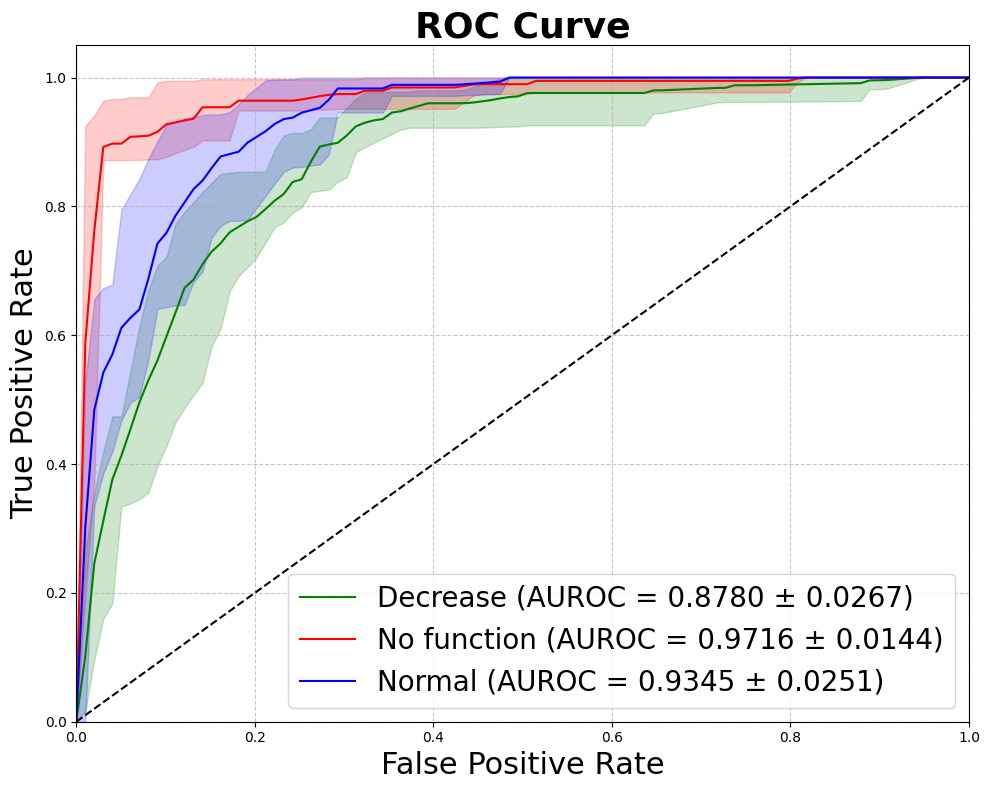

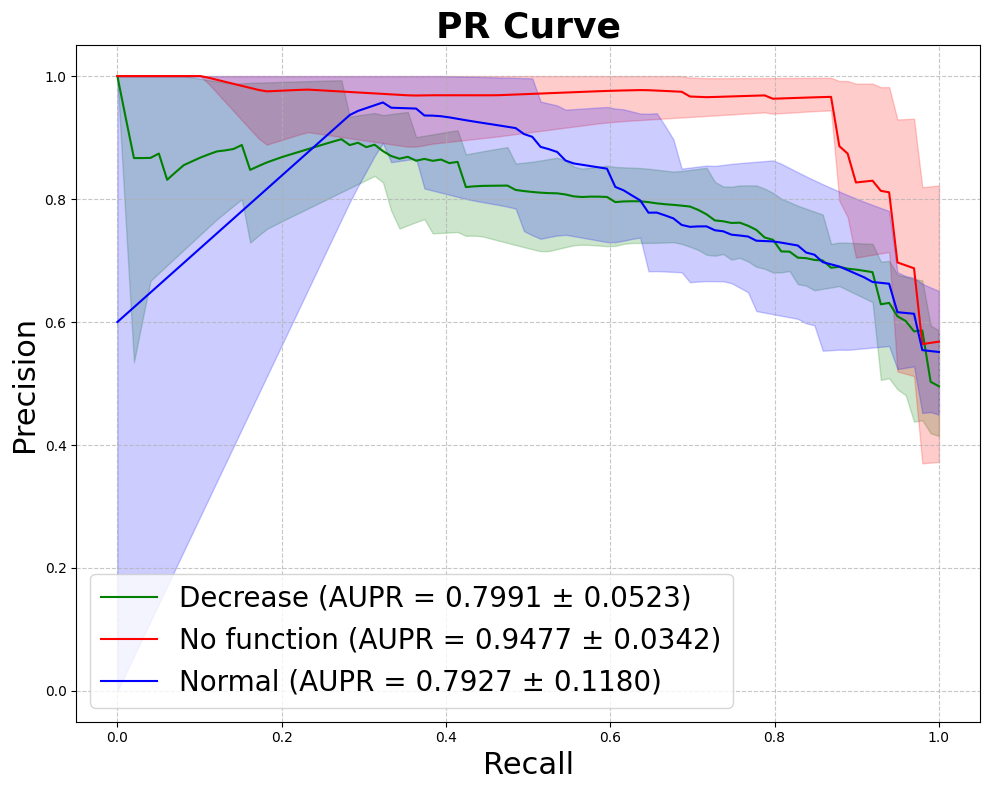

In [31]:
from scipy import stats
def plot_mean_roc_curve(y_true_list, y_probs_list, num_classes=3, font_size=22):
    plt.figure(figsize=(10, 8))
    mean_fpr = np.linspace(0, 1, 100)
    class_labels = ['Decrease', 'No function', 'Normal']
    colors = ['green', 'red', 'blue']
    
    for i in range(num_classes):
        tprs = []
        aucs = []
        for y_true, y_probs in zip(y_true_list, y_probs_list):
            fpr, tpr, _ = roc_curve(y_true == i, y_probs[:, i])
            tprs.append(np.interp(mean_fpr, fpr, tpr))
            tprs[-1][0] = 0.0
            aucs.append(auc(fpr, tpr))
        
        mean_tpr = np.mean(tprs, axis=0)
        mean_tpr[-1] = 1.0
        mean_auc = np.mean(aucs)
        std_auc = np.std(aucs)
        
        # Calculate 95% confidence interval
        tprs_upper = np.percentile(tprs, 97.5, axis=0)
        tprs_lower = np.percentile(tprs, 2.5, axis=0)
        
        plt.plot(mean_fpr, mean_tpr, color=colors[i], 
                 label=f'{class_labels[i]} (AUROC = {mean_auc:.4f} ± {std_auc:.4f})')
        plt.fill_between(mean_fpr, tprs_lower, tprs_upper, color=colors[i], alpha=0.2)

    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=font_size)
    plt.ylabel('True Positive Rate', fontsize=font_size)
    plt.title('ROC Curve', fontsize=font_size + 4, fontweight='bold')
    plt.legend(loc='lower right', fontsize=font_size - 2)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

def plot_mean_precision_recall_curve(y_true_list, y_probs_list, num_classes=3, font_size=22):
    plt.figure(figsize=(10, 8))
    mean_recall = np.linspace(0, 1, 100)
    class_labels = ['Decrease', 'No function', 'Normal']
    colors = ['green', 'red', 'blue']
    
    for i in range(num_classes):
        precisions = []
        auprs = []
        for y_true, y_probs in zip(y_true_list, y_probs_list):
            precision, recall, _ = precision_recall_curve(y_true == i, y_probs[:, i])
            precisions.append(np.interp(mean_recall, recall[::-1], precision[::-1]))
            auprs.append(np.trapz(precision, recall))
        
        mean_precision = np.mean(precisions, axis=0)
        mean_aupr = np.mean(auprs)
        std_aupr = np.std(auprs)
        
        # Calculate 95% confidence interval
        precisions_upper = np.percentile(precisions, 97.5, axis=0)
        precisions_lower = np.percentile(precisions, 2.5, axis=0)
        
        plt.plot(mean_recall, mean_precision, color=colors[i],
                 label=f'{class_labels[i]} (AUPR = {abs(mean_aupr):.4f} ± {abs(std_aupr):.4f})')
        plt.fill_between(mean_recall, precisions_lower, precisions_upper, color=colors[i], alpha=0.2)

    plt.xlabel('Recall', fontsize=font_size)
    plt.ylabel('Precision', fontsize=font_size)
    plt.title('PR Curve', fontsize=font_size + 4, fontweight='bold')
    plt.legend(loc='lower left', fontsize=font_size - 2)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

# ROC 및 PR 커브 시각화
plot_mean_roc_curve(all_test_labels_list, all_test_preds_list, num_classes=3)
plot_mean_precision_recall_curve(all_test_labels_list, all_test_preds_list, num_classes=3)